In [1]:
import sys;
sys.path.append('/home/ashesh.ashesh/code/Disentangle')

In [55]:
from disentangle.data_loader.train_val_data import get_train_val_data
from disentangle.config_utils import load_config
from disentangle.scripts.evaluate import get_data_dir
from disentangle.core.data_split_type import DataSplitType
from disentangle.core.tiff_reader import save_tiff, load_tiff
import os

gt_root_dir = "/group/jug/ashesh/kth_data"
pred_rootdir = "/group/jug/ashesh/training/disentangle"
output_data_dir = "/group/jug/ashesh/naturemethods/three_splitting/"
KTH_SAMPLE = 1
# cropped_Input_2405_D18-M3-S0-L8_16_K1_820-1604-1800-1350


def sample_subdir(k):
    return "kth{}".format(k)


def get_gt_dir(dtype):
    gt_dir = os.path.join(gt_root_dir, dtype)
    gt_dir = os.path.join(gt_dir, sample_subdir(KTH_SAMPLE))
    return gt_dir


def get_kth_gt(val_data):
    if hasattr(val_data, "_data"):
        gt_data = val_data._data[KTH_SAMPLE][0]
    elif isinstance(val_data, list) and isinstance(val_data[0], tuple) and isinstance(val_data[0][1], str):
        assert len(val_data) == 1
        gt_data = val_data[0][0][KTH_SAMPLE]
    else:
        gt_data = val_data[KTH_SAMPLE]
    return gt_data


# /group/jug/ashesh/data/paper_stats/Test_P64_G3-32-32_M50_Sk0/pred_training_disentangle_2507_D33-M3-S0-L8_11_1.tif
full_frame_pred_dirs = {
    # HHMI /group/jug/ashesh/data/paper_stats/Test_P64_G3-32-32_M50_Sk0/pred_training_disentangle_2507_D34-M3-S0-L8_4_1.tif
    # "2507/D34-M3-S0-L8/4": f"/group/jug/ashesh/data/paper_stats/Test_P64_G3-32-32_M50_Sk0/kth_{KTH_SAMPLE}/pred_training_disentangle_2507_D34-M3-S0-L8_4_1.tif",
    # "2507/D33-M3-S0-L8/11": f"/group/jug/ashesh/data/paper_stats/Test_P64_G3-32-32_M50_Sk0/kth_{KTH_SAMPLE}/pred_training_disentangle_2507_D33-M3-S0-L8_11_1.tif",
    # "2507/D33-M3-S0-L8/25": f"/group/jug/ashesh/data/paper_stats/Test_P64_G3-32-32_M50_Sk0/kth_{KTH_SAMPLE}/pred_training_disentangle_2507_D33-M3-S0-L8_25_1.tif"
    # "2505/D32-M3-S0-L8/27": f"/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk0/kth_{KTH_SAMPLE}/pred_training_disentangle_2505_D32-M3-S0-L8_27_1.tif",
    # "2507/D32-M3-S0-L8/0": f"/group/jug/ashesh/data/paper_stats/Test_P64_G3-32-32_M50_Sk0/kth_{KTH_SAMPLE}/pred_training_disentangle_2507_D32-M3-S0-L8_0_1.tif",
    # "2507/D32-M3-S0-L0/5": f"/group/jug/ashesh/data/paper_stats/Test_P64_G3-32-32_M50_Sk0/kth_{KTH_SAMPLE}/pred_training_disentangle_2507_D32-M3-S0-L0_5_1.tif",
    # "2507/D32-M3-S0-L8/7": "/group/jug/ashesh/data/paper_stats/Test_P64_G3-32-32_M50_Sk0/kth_0/pred_training_disentangle_2507_D32-M3-S0-L8_7_1.tif",
    # "2406/D25-M3-S0-L8/4": f"/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk8_F/kth_{KTH_SAMPLE}/pred_training_disentangle_2406_D25-M3-S0-L8_4_1.tif",
    # "2406/D25-M3-S0-L8/5": f"/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk8_F/kth_{KTH_SAMPLE}/pred_training_disentangle_2406_D25-M3-S0-L8_5_1.tif",
    # "2406/D25-M3-S0-L8/6": f"/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk8_F/kth_{KTH_SAMPLE}/pred_training_disentangle_2406_D25-M3-S0-L8_6_1.tif",
    # "2406/D25-M3-S0-L8/14": f"/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk0/kth_{KTH_SAMPLE}/pred_training_disentangle_2406_D25-M3-S0-L8_14_1.tif",
    # "2406/D25-M3-S0-L8/17": f"/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk0/kth_{KTH_SAMPLE}/pred_training_disentangle_2406_D25-M3-S0-L8_17_1.tif",
    # "2406/D25-M3-S0-L8/6": f"/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk8_F/kth_{KTH_SAMPLE}/pred_training_disentangle_2406_D25-M3-S0-L8_6_1.tif",
    # "2406/D25-M3-S0-L8/14" : f'/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk0_F/kth_{KTH_SAMPLE}/pred_training_disentangle_2406_D25-M3-S0-L8_14_1.tif',
    # "2406/D25-M3-S0-L8/17": f'/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk0_F/kth_{KTH_SAMPLE}/pred_training_disentangle_2406_D25-M3-S0-L8_17_1.tif',
    # '2405/D25-M3-S0-L8/2': f'/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk8_F/kth_{KTH_SAMPLE}/pred_training_disentangle_2405_D25-M3-S0-L8_2_1.tif',
    # '2405/D25-M3-S0-L8/3': f'/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk8_F/kth_{KTH_SAMPLE}/pred_training_disentangle_2405_D25-M3-S0-L8_3_1.tif',
    "2405/D18-M3-S0-L8/16": f"/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk0_F/kth_{KTH_SAMPLE}/pred_training_disentangle_2405_D18-M3-S0-L8_16_1.tif",
    # '2506/D30-M3-S0-L8/6': f'/group/jug/ashesh/data/paper_stats/Test_P64_G3-32-32_M50_Sk0/kth_{KTH_SAMPLE}/pred_training_disentangle_2506_D30-M3-S0-L8_6_1.tif'
    # '2506/D30-M3-S0-L8/5':f'/group/jug/ashesh/data/paper_stats/Test_P64_G3-32-32_M50_Sk0/kth_{KTH_SAMPLE}/pred_training_disentangle_2506_D30-M3-S0-L8_5_1.tif'
    # '2412/D30-M3-S0-L8/0':  f'/group/jug/ashesh/data/paper_stats/Test_P64_G5-32-32_M20_Sk0/kth_{KTH_SAMPLE}/pred_training_disentangle_2412_D30-M3-S0-L8_0_1.tif',
    # '2411/D30-M3-S0-L8/26': f'/group/jug/ashesh/data/paper_stats/Test_P64_G5-32-32_M20_Sk0/kth_{KTH_SAMPLE}/pred_training_disentangle_2411_D30-M3-S0-L8_26_1.tif',
}


crops_pred_dirs = {
    # '2404/D21-M3-S0-L8/6':'/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk0/stats_disentangle_2404_D21-M3-S0-L8_6.pkl',
    # '2404/D25-M3-S0-L8/97':'/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk0/stats_disentangle_2404_D25-M3-S0-L8_97.pkl',
    # '2404/D25-M3-S0-L8/120':'/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk0/stats_disentangle_2404_D25-M3-S0-L8_120.pkl',
    # '2404/D25-M3-S0-L8/111':'/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk0/stats_disentangle_2404_D25-M3-S0-L8_111.pkl',
    # '2404/D25-M3-S0-L8/125':'/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk0/stats_disentangle_2404_D25-M3-S0-L8_125.pkl',
    # '2404/D25-M3-S0-L8/139':'/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk0/stats_disentangle_2404_D25-M3-S0-L8_139.pkl',
    # '2404/D25-M3-S0-L8/143':'/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk0/stats_disentangle_2404_D25-M3-S0-L8_143.pkl',
    # '2405/D18-M3-S0-L8/13':'/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk0/stats_disentangle_2405_D18-M3-S0-L8_13.pkl',
    # '2405/D18-M3-S0-L8/14':'/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk0/stats_disentangle_2405_D18-M3-S0-L8_14.pkl',
    # '2405/D18-M3-S0-L8/15':'/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk0/stats_disentangle_2405_D18-M3-S0-L8_15.pkl',
    # '2405/D18-M3-S0-L8/10':'/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk0/stats_disentangle_2405_D18-M3-S0-L8_10.pkl',
    # '2405/D18-M3-S0-L8/11':'/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk0/stats_disentangle_2405_D18-M3-S0-L8_11.pkl',
    # '2405/D18-M3-S0-L8/12':'/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk0/stats_disentangle_2405_D18-M3-S0-L8_12.pkl',
    # '2404/D17-M3-S0-L8/4':'/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk0/stats_disentangle_2404_D17-M3-S0-L8_4.pkl',
    # '2404/D21-M3-S0-L8/1':'/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk0/stats_disentangle_2404_D21-M3-S0-L8_1.pkl',
}


resolution_nm_dict = {
    # '2404/D21-M3-S0-L8/6': 110,
    '2405/D18-M3-S0-L8/16': 27,
    # '2412/D30-M3-S0-L8/0': 300,
    # '2411/D30-M3-S0-L8/26': 196,
    "2506/D30-M3-S0-L8/5": 196,
    "2506/D30-M3-S0-L8/6": 300,
    "2507/D34-M3-S0-L8/4": 45 * 4,
    "2507/D33-M3-S0-L8/25": 45,
    "2507/D32-M3-S0-L8/0": 45,
    "2507/D33-M3-S0-L8/11": 45,
    "2505/D32-M3-S0-L8/27": 45,
    "2507/D32-M3-S0-L0/5": 45,
    "2406/D25-M3-S0-L8/4": 285,
    "2406/D25-M3-S0-L8/5": 285,
    "2406/D25-M3-S0-L8/6": 285,
    "2406/D25-M3-S0-L8/14": 285,
    "2406/D25-M3-S0-L8/17": 285,
}

### Fetch the kth frame data and store it for fast access

In [56]:
for model_dir, pred_fpath in full_frame_pred_dirs.items():
    dtype = model_dir.split("/")[1].split("-")[0]
    gt_dir = get_gt_dir(dtype)

    if not os.path.exists(gt_dir):
        print("No such dir {}. Creating it".format(gt_dir))
        os.makedirs(gt_dir, exist_ok=True)

    gt_fpath = os.path.join(gt_dir, "gt_for_" + os.path.basename(pred_fpath))
    if not os.path.exists(gt_fpath):
        print("GT data is not present at {}. Creating it".format(gt_fpath))
        # loading directory.
        config = load_config(os.path.join(pred_rootdir, model_dir, "config.pkl"))
        val_data = get_train_val_data(
            config.data,
            get_data_dir(int(dtype[1:])),
            DataSplitType.Test,
            val_fraction=config.training.val_fraction,
            test_fraction=config.training.test_fraction,
        )
        kth_gt = get_kth_gt(val_data)
        save_tiff(gt_fpath, kth_gt)


In [57]:
gt_fpath

'/group/jug/ashesh/kth_data/D18/kth1/gt_for_pred_training_disentangle_2405_D18-M3-S0-L8_16_1.tif'

In [58]:
# dtype = key.split('/')[1].split('-')[0]
# config = load_config(os.path.join(pred_rootdir, key, 'config.pkl'))
# val_data = get_train_val_data(config.data, get_data_dir(int(dtype[1:])), DataSplitType.Test,
#         val_fraction=config.training.val_fraction,
#         test_fraction=config.training.test_fraction)
# kth_gt = get_kth_gt(val_data)

### Loading data

In [59]:
from disentangle.core.tiff_reader import load_tiff
from tqdm import tqdm

gt_pred_dict = {}
for model_dir, pred_fpath in tqdm(full_frame_pred_dirs.items()):
    dtype = model_dir.split("/")[1].split("-")[0]
    gt_dir = get_gt_dir(dtype)
    gt_fpath = os.path.join(gt_dir, "gt_for_" + os.path.basename(pred_fpath))
    kth_gt = load_tiff(gt_fpath)
    kth_pred = load_tiff(pred_fpath)
    print(pred_fpath, kth_gt.shape, kth_pred.shape)
    gt_pred_dict[model_dir] = (kth_gt, kth_pred)


100%|██████████| 1/1 [00:00<00:00,  6.40it/s]

/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk0_F/kth_1/pred_training_disentangle_2405_D18-M3-S0-L8_16_1.tif (4096, 4096, 3) (1, 4096, 4096, 3)


In [60]:
# https://www.notion.so/Evaluating-2-channel-results-281cea8bb51c47ccadd50a389614100f?pvs=4

keys = [
    # '2405/D25-M3-S0-L8/2',
    # '2405/D25-M3-S0-L8/3',
    '2405/D18-M3-S0-L8/16',
    # "2406/D25-M3-S0-L8/4",
    # "2406/D25-M3-S0-L8/5",
    # "2406/D25-M3-S0-L8/6",
    # "2406/D25-M3-S0-L8/14",
    # "2406/D25-M3-S0-L8/17",
    # '2412/D30-M3-S0-L8/0',
    # '2411/D30-M3-S0-L8/26'
    # "2406/D25-M3-S0-L8/17"
    # '2506/D30-M3-S0-L8/6'
    # "2506/D30-M3-S0-L8/5",
    # HHMI
    # "2507/D33-M3-S0-L8/25"
    # "2507/D33-M3-S0-L8/11"
    # "2507/D32-M3-S0-L8/0",
    # "2505/D32-M3-S0-L8/27"
    # "2507/D34-M3-S0-L8/4"
    # "2507/D32-M3-S0-L0/5"
]

In [61]:
import matplotlib.pyplot as plt
import numpy as np
from splitting_notebooks_utils import get_input, get_config_from_saved_predictionfile_NM, get_gaussian_poisson_factors

key = keys[-1]
cfg = get_config_from_saved_predictionfile_NM(full_frame_pred_dirs[key])
gaussian_sigma, poisson_noise_factor = get_gaussian_poisson_factors(cfg)
print(key)

2405/D18-M3-S0-L8/16


In [62]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.patches as patches
import pandas as pd

# 5x10 grid for the input. 2x10 grid for the two targets and predictions.


def get_cropped_img(inp, hfac, hs=None, ws=None, wN=None, extra_h=0, extra_w=0):
    if wN is None:
        wN = inp.shape[1]

    if ws is None:
        ws = (inp.shape[1] - wN) // 2
    else:
        assert ws + wN < inp.shape[1], f"Invalid ws for the input. ws = {ws}, wN = {wN}, inp.shape = {inp.shape}"

    hN = int(wN * hfac)
    if hs is None:
        hs = (inp.shape[0] - hN) // 2
    else:
        assert hs + hN < inp.shape[0], f"Invalid hs for the input. hs = {hs}, hN = {hN}, inp.shape = {inp.shape}"

    coords = (hs - extra_h // 2, ws - extra_w // 2, hN + extra_h // 2, wN + extra_w // 2)
    return inp[hs - extra_h // 2 : hs + hN + extra_h // 2, ws - extra_w // 2 : ws + wN + extra_w // 2], coords


def find_most_interesting_box(inp_crop, channel_h_factor):
    """
    Returns hs, the start of the box
    """
    boxH = int(np.ceil(channel_h_factor * inp_crop.shape[0]))
    idx = np.argmax(pd.Series(inp_crop.std(axis=1)).rolling(window=boxH).mean().iloc[boxH:].values)
    return idx

In [63]:
len(gt_pred_dict[key])

2

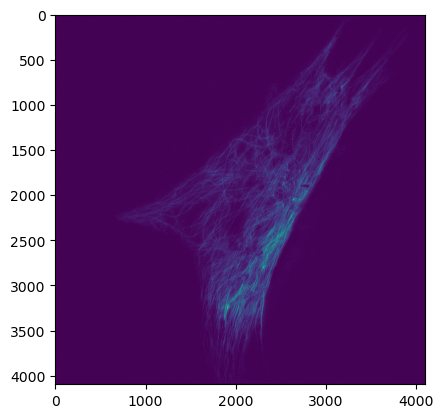

In [64]:
plt.imshow(gt_pred_dict[key][1][0,..., 2])

In [65]:
# cropped_Input_2405_D18-M3-S0-L8_16_K1_820-1604-1800-1350

In [66]:
input_h_factor = 0.75
# wN = 400
# tar_wN = 300
ws = 820 
hs = 1604
wN = 1800
tar_wN = 800
tar_h_factor = 0.75

# Target crop
# tar_h_factor = 0.75
tar_hN = int(tar_h_factor * tar_wN)

savefig = True

if savefig is False:
    hs = np.random.randint(0, gt_pred_dict[key][0].shape[0] - int(wN * input_h_factor))
    ws = np.random.randint(0, gt_pred_dict[key][0].shape[1] - wN)
    print("ws", ws, "hs", hs)

In [69]:
savefig=True

Synthetic input
(1604, 820, 1350, 1800) 1604 820 1800
/group/jug/ashesh/naturemethods/three_splitting/cropped_Input_2405_D18-M3-S0-L8_16_K1_820-1604-1800-1350.svg


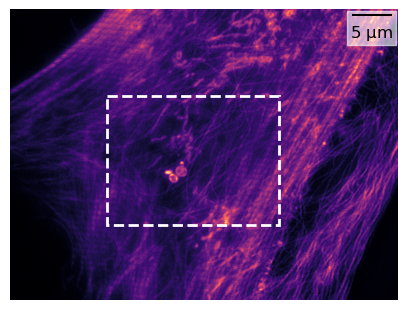

In [73]:
from matplotlib_scalebar.scalebar import ScaleBar

# Input crop
_, ax_inp = plt.subplots(figsize=(5, 5))

key = keys[0]
gt, pred = gt_pred_dict[key]
gt = gt.squeeze()
pred = pred.squeeze()
inp = get_input(gt, pred.shape[-1], gaussian_sigma, poisson_noise_factor)[0]
inp_crop, input_coordinates = get_cropped_img(inp, input_h_factor, wN=wN, ws=ws, hs=hs)
print(input_coordinates, hs, ws, wN)
ax_inp.imshow(inp_crop, cmap="magma")

if key in resolution_nm_dict:
    scalebar = ScaleBar(
        resolution_nm_dict[key],
        "nm",
        # length_fraction=0.1,
        box_alpha=0.6,
        frameon=True,
        location="upper right",
        font_properties={"size": 12},
    )

    ax_inp.add_artist(scalebar)

if savefig:
    ax_inp.axis("off")


# =============================================
# Set the top-left location
tar_rel_hs = 400
tar_rel_ws = 450
relative_coordinates = (tar_rel_hs, tar_rel_ws, tar_hN, tar_wN)
assert tar_rel_hs + tar_hN < inp_crop.shape[0], (
    f"Invalid tar_rel_hs for the input. tar_rel_hs = {tar_rel_hs}, tar_hN = {tar_hN}, inp_crop.shape = {inp_crop.shape}"
)
assert tar_rel_ws + tar_wN < inp_crop.shape[1], (
    f"Invalid tar_rel_ws for the input. tar_rel_ws = {tar_rel_ws}, tar_wN = {tar_wN}, inp_crop.shape = {inp_crop.shape}"
)

rect = patches.Rectangle(
    (relative_coordinates[1], relative_coordinates[0]),
    relative_coordinates[3],
    relative_coordinates[2],
    linewidth=2,
    edgecolor="w",
    facecolor="none",
    linestyle="--",
)
ax_inp.add_patch(rect)

if savefig:
    # filename should contain all cropping information
    fname = "cropped_Input_{}_K{}_{}-{}-{}-{}.svg".format(
        key.replace("/", "_"),
        KTH_SAMPLE,
        input_coordinates[1],
        input_coordinates[0],
        input_coordinates[3],
        input_coordinates[2],
    )

    fpath = os.path.join(output_data_dir, fname)
    print(fpath)
    plt.savefig(fpath, dpi=150, bbox_inches="tight")


In [71]:
tar_hs = tar_rel_hs + input_coordinates[0]
tar_ws = tar_rel_ws + input_coordinates[1]
print(tar_hs, tar_ws, input_coordinates[:2])

2004 1270 (1604, 820)


/group/jug/ashesh/naturemethods/three_splitting/cropped_TarPred_2405_D18-M3-S0-L8_16_K1_2004-1270-600-800.pdf


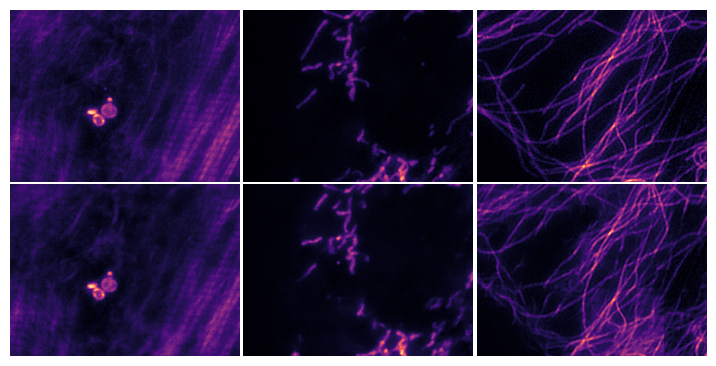

In [72]:
ncols = 3
nrows = 2
img_sz = 3
_, ax = plt.subplots(figsize=(ncols * img_sz, nrows * img_sz * tar_h_factor), ncols=ncols, nrows=nrows)

tar_hs = tar_rel_hs + input_coordinates[0]
tar_ws = tar_rel_ws + input_coordinates[1]
gt_crop = gt[tar_hs : tar_hs + tar_hN, tar_ws : tar_ws + tar_wN]
pred_crop = pred[tar_hs : tar_hs + tar_hN, tar_ws : tar_ws + tar_wN]
for i in range(ncols):
    vmin = None #np.quantile(gt_crop[..., i], 0.001)
    vmax = None #np.quantile(gt_crop[..., i], 0.999)
    ax[0, i].imshow(gt_crop[..., i], vmin=vmin, vmax=vmax, cmap="magma")
    ax[1, i].imshow(pred_crop[..., i], vmin=vmin, vmax=vmax, cmap="magma")
    ax[0, i].axis("off")
    ax[1, i].axis("off")

# reduce the space between the subplots
plt.subplots_adjust(wspace=0.01, hspace=0.01)

if savefig:
    # filename should contain all cropping information
    fname = "cropped_TarPred_{}_K{}_{}-{}-{}-{}.pdf".format(
        key.replace("/", "_"), KTH_SAMPLE, tar_hs, tar_ws, tar_hN, tar_wN
    )
    fpath = os.path.join(output_data_dir, fname)
    print(fpath)
    plt.savefig(fpath, dpi=150, bbox_inches="tight")

In [52]:
pred.max(), gt.max()

(np.uint32(13115), np.float32(963.497))

In [ ]:
fname = "cropped_TarPred_{}_K{}_{}-{}-{}-{}.png".format(
    key.replace("/", "_"), KTH_SAMPLE, tar_hs, tar_ws, tar_hN, tar_wN
)
fpath = os.path.join(output_data_dir, fname)
print(fpath)


In [ ]:
from disentangle.core.tiff_reader import load_tiff

fpath = (
    "/group/jug/ashesh/data/paper_stats/Test_P64_G3-32-32_M50_Sk0/pred_training_disentangle_2507_D33-M3-S0-L8_25_1.tif"
)
data = load_tiff(fpath)

In [ ]:
import matplotlib.pyplot as plt

plt.imshow(data[0, 0, 4, ..., 0])
data.shape